## El algoritmo 2.1
Para encontrar una solución de $f(x)=0$, con $f$ continua en $[a,b]$ y $f(a)$, $f(b)$ de signos opuestos:

```text
ENTRADA  a, b; tolerancia TOL; número máximo de iteraciones N0.
SALIDA   solución aproximada p o mensaje de falla.

Paso 1  Tome i = 1 y FA = f(a).
Paso 2  Mientras i <= N0 haga los pasos 3 a 6.
Paso 3      Tome p = a + (b - a) / 2 y FP = f(p).
Paso 4      Si FP = 0 o (b - a) / 2 < TOL: SALIDA (p); PARE.
Paso 5      Tome i = i + 1.
Paso 6      Si FA · FP > 0: tome a = p y FA = FP; si no, tome b = p.
Paso 7  SALIDA ("El método fracasó después de N0 iteraciones"); PARE.
```

**Teorema 22.1**. Si $f∈C[a,b]$ y $f(a)⋅f(b)<0$, la bisección genera una sucesión {$p_n​$} que aproxima un cero $p$ de $f$ con

In [2]:
def biseccion(f, a, b, TOL=1e-6, N0=100):
    """Devuelve (p, historia), con historia = [(i, a, b, p) por iteración]."""
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a + (b-a)/2                             
        FP = f(p)
        historia.append((i,a, b, p))                        
        if FP == 0 or (b-a)/2 < TOL:                          
            return p, historia
        i = i + 1
        if FA * FP > 0:
            a = p                                     
            FA = FP
        else:
            b = p                                     
    raise RuntimeError(f"fracasó después de {N0} iteraciones")


La ecuación $x^3−x−1=0$ tiene una solución en $[1,2]$. Se busca una aproximación con precisión de $10^{−4}$.

In [3]:
def f(x):
    return x**3 -x -1

biseccion(f, 1, 2 , 1e-4)

(1.32476806640625,
 [(1, 1, 2, 1.5),
  (2, 1, 1.5, 1.25),
  (3, 1.25, 1.5, 1.375),
  (4, 1.25, 1.375, 1.3125),
  (5, 1.3125, 1.375, 1.34375),
  (6, 1.3125, 1.34375, 1.328125),
  (7, 1.3125, 1.328125, 1.3203125),
  (8, 1.3203125, 1.328125, 1.32421875),
  (9, 1.32421875, 1.328125, 1.326171875),
  (10, 1.32421875, 1.326171875, 1.3251953125),
  (11, 1.32421875, 1.3251953125, 1.32470703125),
  (12, 1.32470703125, 1.3251953125, 1.324951171875),
  (13, 1.32470703125, 1.324951171875, 1.3248291015625),
  (14, 1.32470703125, 1.3248291015625, 1.32476806640625)])

Use la bisección con $TOL=10^{−2}$ para encontrar las soluciones de
$$x3−7x2+14x−6=0$$
en los intervalos $[0,1]$, $[1,3.2]$ y $[3.2,4]$.

In [4]:
#intervalo [0,1]
def f(x):
    return x**3 - 7*x**2 +14*x - 6

biseccion(f, 0, 1, 1e-2)

(0.5859375,
 [(1, 0, 1, 0.5),
  (2, 0.5, 1, 0.75),
  (3, 0.5, 0.75, 0.625),
  (4, 0.5, 0.625, 0.5625),
  (5, 0.5625, 0.625, 0.59375),
  (6, 0.5625, 0.59375, 0.578125),
  (7, 0.578125, 0.59375, 0.5859375)])

In [5]:
#intervalo [1,3.2]
biseccion(f, 1, 3.2, 1e-2)

(3.0023437500000005,
 [(1, 1, 3.2, 2.1),
  (2, 2.1, 3.2, 2.6500000000000004),
  (3, 2.6500000000000004, 3.2, 2.9250000000000003),
  (4, 2.9250000000000003, 3.2, 3.0625),
  (5, 2.9250000000000003, 3.0625, 2.9937500000000004),
  (6, 2.9937500000000004, 3.0625, 3.028125),
  (7, 2.9937500000000004, 3.028125, 3.0109375000000003),
  (8, 2.9937500000000004, 3.0109375000000003, 3.0023437500000005)])

In [6]:
#intervalo [3.2,4]
biseccion(f, 3.2, 4, 1e-2)

(3.41875,
 [(1, 3.2, 4, 3.6),
  (2, 3.2, 3.6, 3.4000000000000004),
  (3, 3.4000000000000004, 3.6, 3.5),
  (4, 3.4000000000000004, 3.5, 3.45),
  (5, 3.4000000000000004, 3.45, 3.4250000000000003),
  (6, 3.4000000000000004, 3.4250000000000003, 3.4125000000000005),
  (7, 3.4125000000000005, 3.4250000000000003, 3.41875)])

Antes de aplicar la bisección, grafique las dos curvas de cada ecuación para elegir un intervalo con cambio de signo.

Con $TOL={10−5}$, encuentre el primer valor positivo de $x$ que cumple $x=2sinx$.

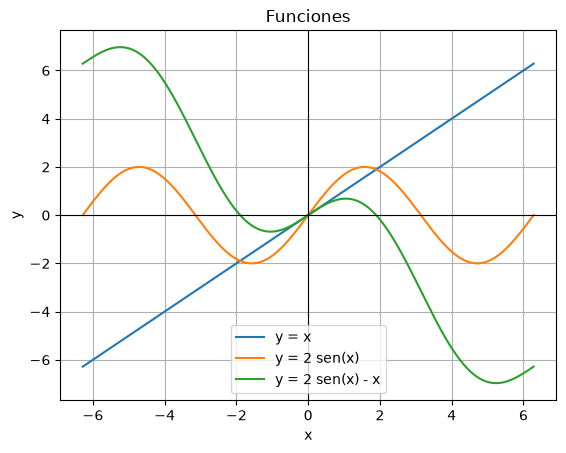

In [7]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2*np.pi, 2*np.pi, 1000)

y1 = x
y2 = 2*np.sin(x)

# f(x) = 2xsen(x) -x
y3 = 2*np.sin(x)-x

plt.plot(x, y1, label='y = x')
plt.plot(x, y2, label='y = 2 sen(x)')
plt.plot(x, y3, label='y = 2 sen(x) - x')

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.grid(True)
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Funciones')
plt.show()

In [8]:
# intervalo [1.5,2]
def f(x):
    return 2*np.sin(x)-x

biseccion(f, 1.5, 2, 1e-5)

(1.8955001831054688,
 [(1, 1.5, 2, 1.75),
  (2, 1.75, 2, 1.875),
  (3, 1.875, 2, 1.9375),
  (4, 1.875, 1.9375, 1.90625),
  (5, 1.875, 1.90625, 1.890625),
  (6, 1.890625, 1.90625, 1.8984375),
  (7, 1.890625, 1.8984375, 1.89453125),
  (8, 1.89453125, 1.8984375, 1.896484375),
  (9, 1.89453125, 1.896484375, 1.8955078125),
  (10, 1.89453125, 1.8955078125, 1.89501953125),
  (11, 1.89501953125, 1.8955078125, 1.895263671875),
  (12, 1.895263671875, 1.8955078125, 1.8953857421875),
  (13, 1.8953857421875, 1.8955078125, 1.89544677734375),
  (14, 1.89544677734375, 1.8955078125, 1.895477294921875),
  (15, 1.895477294921875, 1.8955078125, 1.8954925537109375),
  (16, 1.8954925537109375, 1.8955078125, 1.8955001831054688)])

Con $TOL=10^{−5}$, encuentre el primer valor positivo de $x$ que cumple $x=tanx$.

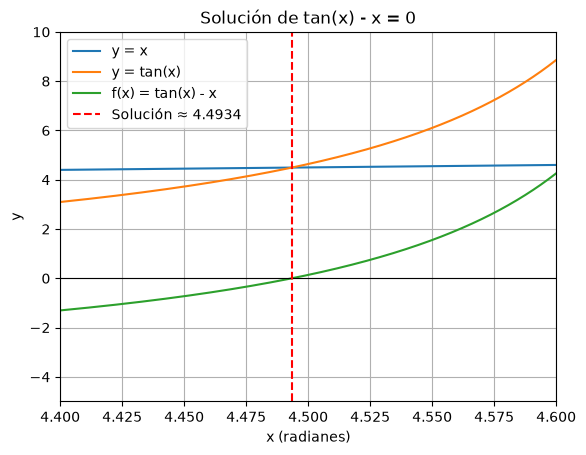

In [9]:
x = np.linspace(4.4, 4.6, 2000)

y1 = x
y2 = np.tan(x)
y3 = np.tan(x) - x

plt.plot(x, y1, label='y = x')
plt.plot(x, y2, label='y = tan(x)')
plt.plot(x, y3, label='f(x) = tan(x) - x')

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(4.4934, color='red', linestyle='--',
            label='Solución ≈ 4.4934')

plt.xlim(4.4, 4.6)
plt.ylim(-5, 10)
plt.grid(True)
plt.xlabel('x (radianes)')
plt.ylabel('y')
plt.title('Solución de tan(x) - x = 0')
plt.legend()
plt.show()

In [10]:
#intervalo [4.2,4.6]
def f(x):
    return np.tan(x) - x
biseccion(f, 4.2, 4.6, 1e-5)

(4.493414306640625,
 [(1, 4.2, 4.6, 4.4),
  (2, 4.4, 4.6, 4.5),
  (3, 4.4, 4.5, 4.45),
  (4, 4.45, 4.5, 4.475),
  (5, 4.475, 4.5, 4.4875),
  (6, 4.4875, 4.5, 4.49375),
  (7, 4.4875, 4.49375, 4.490625),
  (8, 4.490625, 4.49375, 4.4921875),
  (9, 4.4921875, 4.49375, 4.49296875),
  (10, 4.49296875, 4.49375, 4.493359375000001),
  (11, 4.493359375000001, 4.49375, 4.4935546875000005),
  (12, 4.493359375000001, 4.4935546875000005, 4.493457031250001),
  (13, 4.493359375000001, 4.493457031250001, 4.493408203125001),
  (14, 4.493408203125001, 4.493457031250001, 4.493432617187501),
  (15, 4.493408203125001, 4.493432617187501, 4.493420410156251),
  (16, 4.493408203125001, 4.493420410156251, 4.493414306640625)])

Con $TOL=10^{−3}$, encuentre la solución de $x^{2}−1=e^{1−x2}$ en $[−2,0]$.

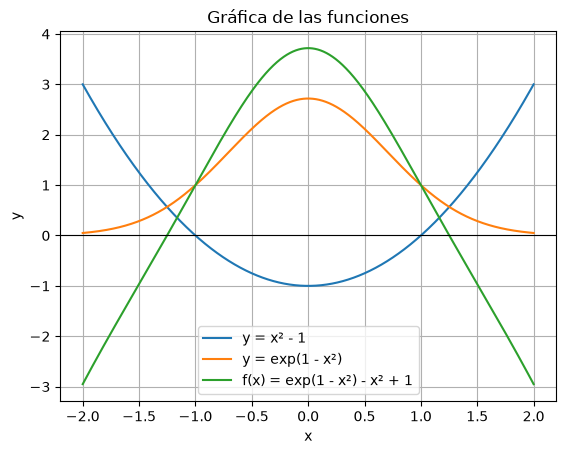

In [11]:

x = np.linspace(-2, 2, 2000)

y1 = x**2 - 1
y2 = np.exp(1 - x**2)
y3 = y2 - y1

plt.plot(x, y1, label='y = x² - 1')
plt.plot(x, y2, label='y = exp(1 - x²)')
plt.plot(x, y3, label='f(x) = exp(1 - x²) - x² + 1')

plt.axhline(0, color='black', linewidth=0.8)
plt.grid(True)
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Gráfica de las funciones')
plt.show()

In [12]:
#intervalo [1, 1.5]

biseccion(f, -2, 0, 1e-3)

(-1.5712890625,
 [(1, -2, 0, -1.0),
  (2, -2, -1.0, -1.5),
  (3, -2, -1.5, -1.75),
  (4, -1.75, -1.5, -1.625),
  (5, -1.625, -1.5, -1.5625),
  (6, -1.625, -1.5625, -1.59375),
  (7, -1.59375, -1.5625, -1.578125),
  (8, -1.578125, -1.5625, -1.5703125),
  (9, -1.578125, -1.5703125, -1.57421875),
  (10, -1.57421875, -1.5703125, -1.572265625),
  (11, -1.572265625, -1.5703125, -1.5712890625)])

Sea
    $$ f(x) = (x+3)(x+1)^2x(x-1)^3(x-3), $$
cuyos ceros son −3, −1 (doble), 0, 1 (triple) y 3.

¿A qué cero converge la bisección en cada intervalo? Escriba los ceros en este orden: [−3.5, 2.5], [−1.5, 0.6], [0.4, 2.2], [2, 3.7].

In [13]:
#intervalo [-3.5, 2.5]
def f(x):
    return (x+3)* (x+1)**2 * x* (x-1)**3 * (x-3)

biseccion(f, -3.5, 2.5)

(-2.999999761581421,
 [(1, -3.5, 2.5, -0.5),
  (2, -3.5, -0.5, -2.0),
  (3, -3.5, -2.0, -2.75),
  (4, -3.5, -2.75, -3.125),
  (5, -3.125, -2.75, -2.9375),
  (6, -3.125, -2.9375, -3.03125),
  (7, -3.03125, -2.9375, -2.984375),
  (8, -3.03125, -2.984375, -3.0078125),
  (9, -3.0078125, -2.984375, -2.99609375),
  (10, -3.0078125, -2.99609375, -3.001953125),
  (11, -3.001953125, -2.99609375, -2.9990234375),
  (12, -3.001953125, -2.9990234375, -3.00048828125),
  (13, -3.00048828125, -2.9990234375, -2.999755859375),
  (14, -3.00048828125, -2.999755859375, -3.0001220703125),
  (15, -3.0001220703125, -2.999755859375, -2.99993896484375),
  (16, -3.0001220703125, -2.99993896484375, -3.000030517578125),
  (17, -3.000030517578125, -2.99993896484375, -2.9999847412109375),
  (18, -3.000030517578125, -2.9999847412109375, -3.0000076293945312),
  (19, -3.0000076293945312, -2.9999847412109375, -2.9999961853027344),
  (20, -3.0000076293945312, -2.9999961853027344, -3.000001907348633),
  (21, -3.0000019073

In [14]:
#intervalo [-1.5, 0.5]
def f(x):
    return (x+3)* (x+1)**2 * x* (x-1)**3 * (x-3)

biseccion(f, -1.5, 0.6)

(-2.1457672122312687e-07,
 [(1, -1.5, 0.6, -0.44999999999999996),
  (2, -0.44999999999999996, 0.6, 0.07499999999999996),
  (3, -0.44999999999999996, 0.07499999999999996, -0.1875),
  (4, -0.1875, 0.07499999999999996, -0.05625000000000002),
  (5, -0.05625000000000002, 0.07499999999999996, 0.009374999999999967),
  (6, -0.05625000000000002, 0.009374999999999967, -0.023437500000000028),
  (7, -0.023437500000000028, 0.009374999999999967, -0.0070312500000000305),
  (8, -0.0070312500000000305, 0.009374999999999967, 0.001171874999999968),
  (9, -0.0070312500000000305, 0.001171874999999968, -0.0029296875000000312),
  (10, -0.0029296875000000312, 0.001171874999999968, -0.0008789062500000316),
  (11, -0.0008789062500000316, 0.001171874999999968, 0.00014648437499996825),
  (12,
   -0.0008789062500000316,
   0.00014648437499996825,
   -0.00036621093750003166),
  (13,
   -0.00036621093750003166,
   0.00014648437499996825,
   -0.0001098632812500317),
  (14, -0.0001098632812500317, 0.000146484374999968

In [15]:
#intervalo [0.4, 2.2]
def f(x):
    return (x+3)* (x+1)**2 * x* (x-1)**3 * (x-3)

biseccion(f, 0.4, 2.2)

(1.0000002861022952,
 [(1, 0.4, 2.2, 1.3000000000000003),
  (2, 0.4, 1.3000000000000003, 0.8500000000000001),
  (3, 0.8500000000000001, 1.3000000000000003, 1.0750000000000002),
  (4, 0.8500000000000001, 1.0750000000000002, 0.9625000000000001),
  (5, 0.9625000000000001, 1.0750000000000002, 1.0187500000000003),
  (6, 0.9625000000000001, 1.0187500000000003, 0.9906250000000002),
  (7, 0.9906250000000002, 1.0187500000000003, 1.0046875000000002),
  (8, 0.9906250000000002, 1.0046875000000002, 0.9976562500000001),
  (9, 0.9976562500000001, 1.0046875000000002, 1.0011718750000003),
  (10, 0.9976562500000001, 1.0011718750000003, 0.9994140625000002),
  (11, 0.9994140625000002, 1.0011718750000003, 1.0002929687500002),
  (12, 0.9994140625000002, 1.0002929687500002, 0.9998535156250001),
  (13, 0.9998535156250001, 1.0002929687500002, 1.0000732421875003),
  (14, 0.9998535156250001, 1.0000732421875003, 0.9999633789062502),
  (15, 0.9999633789062502, 1.0000732421875003, 1.0000183105468752),
  (16, 0.9999

In [16]:
#intervalo [2, 3.7]
def f(x):
    return (x+3)* (x+1)**2 * x* (x-1)**3 * (x-3)

biseccion(f, 2, 3.7)

(3.0000001430511474,
 [(1, 2, 3.7, 2.85),
  (2, 2.85, 3.7, 3.2750000000000004),
  (3, 2.85, 3.2750000000000004, 3.0625),
  (4, 2.85, 3.0625, 2.95625),
  (5, 2.95625, 3.0625, 3.009375),
  (6, 2.95625, 3.009375, 2.9828124999999996),
  (7, 2.9828124999999996, 3.009375, 2.99609375),
  (8, 2.99609375, 3.009375, 3.002734375),
  (9, 2.99609375, 3.002734375, 2.9994140625),
  (10, 2.9994140625, 3.002734375, 3.0010742187500004),
  (11, 2.9994140625, 3.0010742187500004, 3.000244140625),
  (12, 2.9994140625, 3.000244140625, 2.9998291015625),
  (13, 2.9998291015625, 3.000244140625, 3.00003662109375),
  (14, 2.9998291015625, 3.00003662109375, 2.9999328613281246),
  (15, 2.9999328613281246, 3.00003662109375, 2.9999847412109375),
  (16, 2.9999847412109375, 3.00003662109375, 3.000010681152344),
  (17, 2.9999847412109375, 3.000010681152344, 2.9999977111816407),
  (18, 2.9999977111816407, 3.000010681152344, 3.0000041961669925),
  (19, 2.9999977111816407, 3.0000041961669925, 3.0000009536743164),
  (20, 2.

Un abrevadero de longitud $L$ tiene una sección transversal en forma de semicírculo de radio $r$. Cuando se llena de agua hasta una distancia $h$ **desde la parte superior**, el volumen de agua es
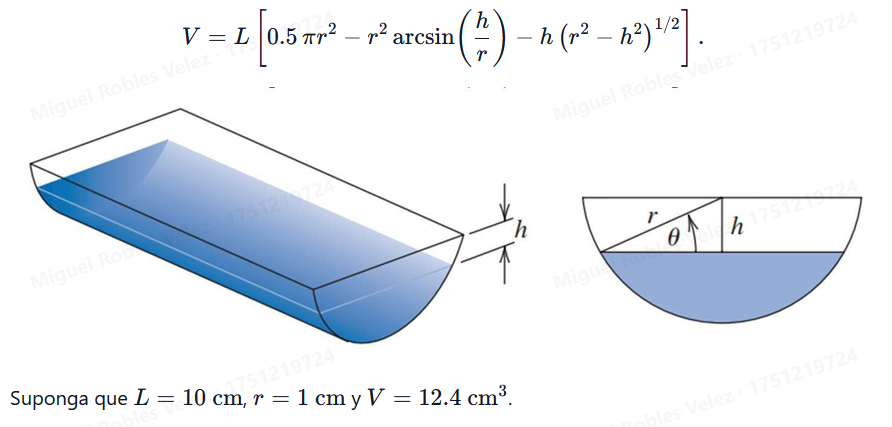

In [17]:
l,r,v = 10,1,12.4

def V(h):
    return (l*(0.5*np.pi*r**2 -r**2*np.arcsin(h/r) - h*(r**2 - h**2)**(1/2)))-v


biseccion(V, 0, r, 0.01)
print(r-biseccion(V, 0, r, 0.01)[0])

0.8359375


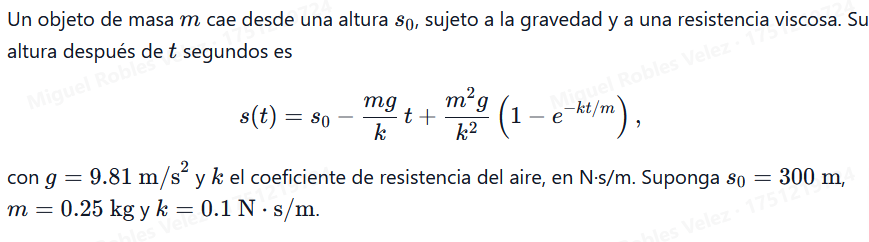

In [18]:
m,g,k = 0.25, 9.81, 0.1
s0 = 300

def s(t):
    return s0 - (m*g)*t/k + (m**2 * g)/ k**2 * (1 - np.exp(-k*t/m))

biseccion(s, 0, 20, 0.01)

(14.716796875,
 [(1, 0, 20, 10.0),
  (2, 10.0, 20, 15.0),
  (3, 10.0, 15.0, 12.5),
  (4, 12.5, 15.0, 13.75),
  (5, 13.75, 15.0, 14.375),
  (6, 14.375, 15.0, 14.6875),
  (7, 14.6875, 15.0, 14.84375),
  (8, 14.6875, 14.84375, 14.765625),
  (9, 14.6875, 14.765625, 14.7265625),
  (10, 14.6875, 14.7265625, 14.70703125),
  (11, 14.70703125, 14.7265625, 14.716796875)])

Grafique $y=x$ y $y=tanx$ en $[0,5]$ (limite el eje y, por ejemplo, a $[−10,10]$) y marque la solución de x=tanx que encontró. Suba la gráfica.

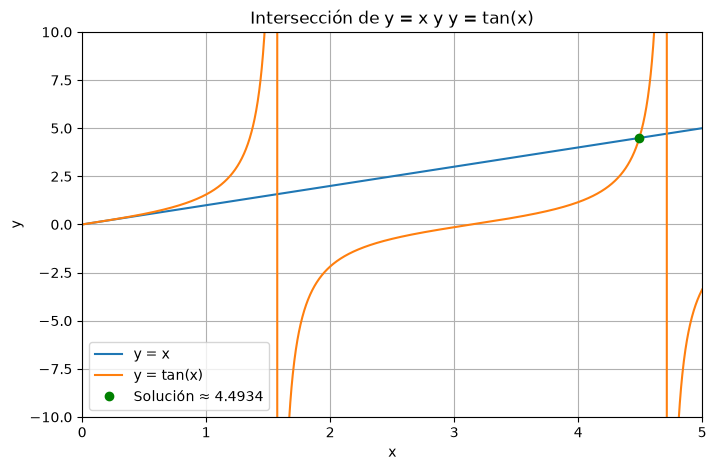

In [19]:

# Solución encontrada
x1 = biseccion(lambda x: np.tan(x) - x, 4, 5)[0]


x = np.linspace(0, 5, 2000)

plt.figure(figsize=(8, 5))
plt.plot(x, x, label='y = x')
plt.plot(x, np.tan(x), label='y = tan(x)')

# Marcar la solución
plt.plot(x1, x1, 'go', label=f'Solución ≈ {x1:.4f}')

plt.xlim(0, 5)
plt.ylim(-10, 10)
plt.grid(True)
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Intersección de y = x y y = tan(x)')

plt.show()